# Rol 1: Codificador. Análisis de la representación
Notebook del Rol 1 (el notebook integrado `final.ipynb` lo edita solo Igor). Usa `src/rol1_codificacion.py` y guarda sus resultados en `results/graficos/rol1_*.png` y `results/tablas/rol1_*.csv`.

| # | Sección | Tarea del Rol 1 |
|---|---|---|
| 1 | Detección de notas del silbido | `extraer_notas` con `pyin` |
| 2 | Transposición | Decidir `TRANSPOSICION` |
| 3 | Tabla de genes y test de la codificación | `GENES`, `codificar` / `decodificar` |
| 4 | Escala lineal vs logarítmica | Justificación de la codificación |
| 5 | Tamaño del espacio de búsqueda | Entregable del informe |
| 6 | Sensibilidad: fitness vs variación de cada gen | Tarea del Día 3 |

Correr con **Kernel → Restart & Run All** (≈ 1 min).

In [1]:
import os, sys, time, importlib, warnings
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, RAIZ); os.chdir(RAIZ)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, librosa, soundfile as sf
from IPython.display import Audio, display

from src import rol1_codificacion as rol1

SEMILLA, SR = 42, rol1.SR
GRAF, TABLAS = "results/graficos", "results/tablas"
for c in (GRAF, TABLAS): os.makedirs(c, exist_ok=True)
RUTA_SILBIDO = "data/silbido.wav"
print("librosa", librosa.__version__, "| numpy", np.__version__)

librosa 1.0.0 | numpy 2.5.3


## 1. Detección de notas del silbido
`extraer_notas` sigue estos pasos:

1. `pyin` (500–3000 Hz) estima la frecuencia de cada frame (11.6 ms) y su probabilidad de tener nota.
2. Se descartan los frames con probabilidad < 0.5, que son ruido.
3. Se corrige el desvío de afinación del silbido.
4. Se aplica un filtro de mediana por tramo, que borra los temblores.
5. Se redondea al semitono.
6. Se agrupan los frames y se aplica la regla de los 80 ms.

El gráfico muestra lo que ve `pyin` (puntos) y las notas que se extraen (barras).

Frames con nota según pyin: 601 | aceptados: 424 | descartados por baja confianza: 177


,midi,nota,frecuencia_Hz,duracion_s
0,88,E6,1318.5,0.499
1,88,E6,1318.5,0.476
2,90,F#6,1480.0,0.488
3,92,G#6,1661.2,0.522
4,92,G#6,1661.2,0.464
5,90,F#6,1480.0,0.464
6,88,E6,1318.5,0.244
7,89,F6,1396.9,0.244
8,86,D6,1174.7,0.093
9,87,D#6,1244.5,0.372


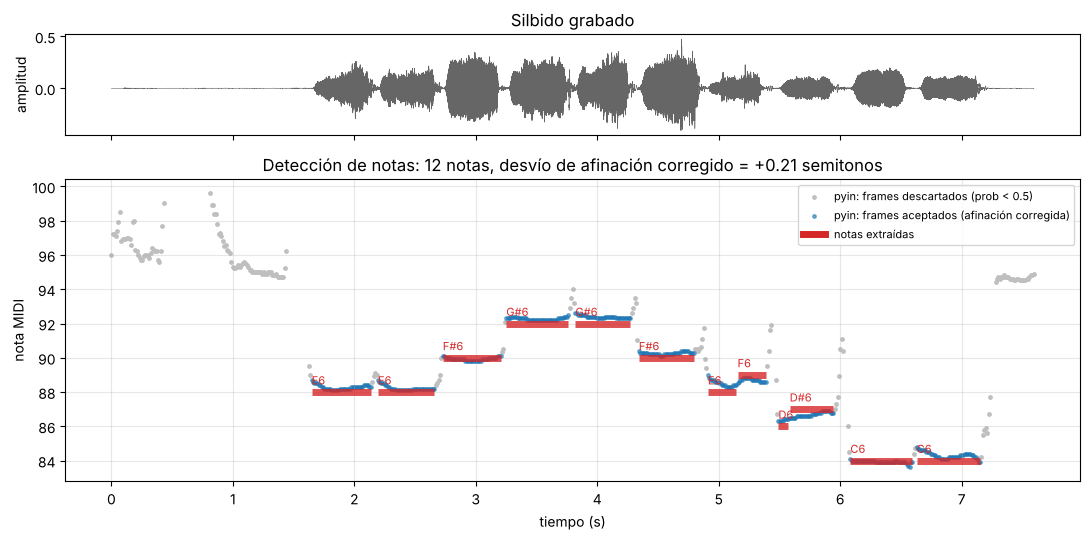

In [2]:
notas, durs = rol1.extraer_notas(RUTA_SILBIDO)

# Se repite el proceso paso a paso SOLO para poder dibujarlo (mismas constantes y funciones del módulo)
y, sr = librosa.load(RUTA_SILBIDO, sr=SR, mono=True)
f0, voz_pyin, prob = librosa.pyin(y, fmin=rol1.FMIN, fmax=rol1.FMAX, sr=sr,
                                  frame_length=rol1.FRAME, hop_length=rol1.HOP)
t = librosa.times_like(f0, sr=sr, hop_length=rol1.HOP)
voz = voz_pyin & (prob >= rol1.UMBRAL_CONFIANZA) & np.isfinite(f0)
midi_crudo = librosa.hz_to_midi(f0)
afinacion = librosa.pitch_tuning(midi_crudo[voz])
suave = rol1._suavizar(np.where(voz, midi_crudo, np.nan) - afinacion, voz, rol1.FILTRO_MEDIANA)
segs = rol1._limpiar(rol1._segmentos(np.where(voz, np.round(suave), -1).astype(int), voz),
                     int(np.ceil(rol1.DUR_MIN * sr / rol1.HOP)))
assert [s[0] for s in segs] == notas  # el dibujo corresponde exactamente a lo que devuelve extraer_notas

fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={"height_ratios": [1, 3]})
ax[0].plot(np.arange(len(y)) / sr, y, lw=0.4, color="0.4"); ax[0].set(ylabel="amplitud", title="Silbido grabado")
descartado = voz_pyin & ~voz
ax[1].scatter(t[descartado], midi_crudo[descartado], s=6, color="0.75", label="pyin: frames descartados (prob < 0.5)")
ax[1].scatter(t[voz], midi_crudo[voz] - afinacion, s=6, color="C0", alpha=0.6, label="pyin: frames aceptados (afinación corregida)")
for nota, ini, fin in segs:
    ax[1].hlines(nota, t[ini], t[fin - 1], color="C3", lw=5, alpha=0.8)
    ax[1].text(t[ini], nota + 0.45, librosa.midi_to_note(nota, unicode=False), fontsize=8, color="C3")
ax[1].plot([], [], color="C3", lw=5, label="notas extraídas")
ax[1].set(xlabel="tiempo (s)", ylabel="nota MIDI", title=f"Detección de notas: {len(notas)} notas, desvío de afinación corregido = {afinacion:+.2f} semitonos")
ax[1].legend(loc="upper right", fontsize=8); ax[1].grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{GRAF}/rol1_deteccion_notas.png", dpi=130)

print(f"Frames con nota según pyin: {voz_pyin.sum()} | aceptados: {voz.sum()} | descartados por baja confianza: {descartado.sum()}")
display(Audio(y, rate=sr))
df_notas = pd.DataFrame({"midi": notas, "nota": [librosa.midi_to_note(n, unicode=False) for n in notas],
                         "frecuencia_Hz": np.round(librosa.midi_to_hz(notas), 1), "duracion_s": durs})
df_notas.to_csv(f"{TABLAS}/rol1_notas_silbido.csv", index_label="n")
df_notas

## 2. Transposición
Un silbido suena 1 o 2 octavas por encima de un instrumento. Cada octava son 12 semitonos MIDI. Se comparan dos opciones: bajar una octava (-12) o dos (-24).

In [3]:
tabla_tr = pd.DataFrame({"silbido": [librosa.midi_to_note(n, unicode=False) for n in notas]})
for tr in (-12, -24):
    tabla_tr[f"{tr:+d}"] = [librosa.midi_to_note(n + tr, unicode=False) for n in notas]
rango = lambda tr: f"{librosa.midi_to_note(min(notas)+tr, unicode=False)}–{librosa.midi_to_note(max(notas)+tr, unicode=False)} " \
                   f"({librosa.midi_to_hz(min(notas)+tr):.0f}–{librosa.midi_to_hz(max(notas)+tr):.0f} Hz)"
for tr in (0, -12, -24):
    print(f"TRANSPOSICION = {tr:+3d}: rango {rango(tr)}")
print("\nNota de referencia del fitness (provisional): A4 = MIDI 69 = 440 Hz")
TRANSPOSICION = -24
print(f"Elegida: TRANSPOSICION = {TRANSPOSICION} -> melodía en {rango(TRANSPOSICION)}, alrededor del Do central y de A4")
tabla_tr.T

TRANSPOSICION =  +0: rango C6–G#6 (1047–1661 Hz)
TRANSPOSICION = -12: rango C5–G#5 (523–831 Hz)
TRANSPOSICION = -24: rango C4–G#4 (262–415 Hz)

Nota de referencia del fitness (provisional): A4 = MIDI 69 = 440 Hz
Elegida: TRANSPOSICION = -24 -> melodía en C4–G#4 (262–415 Hz), alrededor del Do central y de A4


,0,1,2,3,4,5,6,7,8,9,10,11
silbido,E6,E6,F#6,G#6,G#6,F#6,E6,F6,D6,D#6,C6,C6
-12,E5,E5,F#5,G#5,G#5,F#5,E5,F5,D5,D#5,C5,C5
-24,E4,E4,F#4,G#4,G#4,F#4,E4,F4,D4,D#4,C4,C4


## 3. Tabla de genes y test de la codificación
Cada individuo es un vector de 14 números en [0, 1]. `decodificar` lo traduce a valores físicos y `codificar` hace la traducción inversa.

In [4]:
tabla_genes = pd.DataFrame(rol1.GENES, columns=["gen", "mín", "máx", "unidad"])
tabla_genes["escala"] = ["logarítmica" if g in rol1.ESCALA_LOG else "lineal" for g in tabla_genes["gen"]]
tabla_genes["valor con x=0.5"] = [round(v, 4) for v in rol1.decodificar(np.full(rol1.N_GENES, 0.5)).values()]
tabla_genes.to_csv(f"{TABLAS}/rol1_tabla_genes.csv", index_label="posición")

rng = np.random.default_rng(SEMILLA)
X = rng.random((1000, rol1.N_GENES))
assert all(np.allclose(rol1.codificar(rol1.decodificar(x)), x) for x in X)
for extremo in (np.zeros(rol1.N_GENES), np.ones(rol1.N_GENES)):
    assert np.allclose(rol1.codificar(rol1.decodificar(extremo)), extremo)
print("✔ codificar(decodificar(x)) == x  en 1000 vectores aleatorios y en los extremos 0 y 1")
tabla_genes

✔ codificar(decodificar(x)) == x  en 1000 vectores aleatorios y en los extremos 0 y 1


,gen,mín,máx,unidad,escala,valor con x=0.5
0,amp_h1,0.000,1.00,lineal,lineal,0.5000
1,amp_h2,0.000,1.00,lineal,lineal,0.5000
2,amp_h3,0.000,1.00,lineal,lineal,0.5000
3,amp_h4,0.000,1.00,lineal,lineal,0.5000
4,amp_h5,0.000,1.00,lineal,lineal,0.5000
5,amp_h6,0.000,1.00,lineal,lineal,0.5000
6,amp_h7,0.000,1.00,lineal,lineal,0.5000
7,amp_h8,0.000,1.00,lineal,lineal,0.5000
8,ataque,0.005,0.30,s,logarítmica,0.0387
9,decaimiento,0.020,1.00,s,logarítmica,0.1414


## 4. Escala lineal vs logarítmica (genes de tiempo)
El oído percibe los cambios de tiempo de forma **relativa**: pasar de 5 a 10 ms se nota mucho más que pasar de 300 a 305 ms. Se compara qué fracción del gen (y por lo tanto del esfuerzo de búsqueda del AG) cae en cada zona perceptual del ataque.

,zona,% lineal,% logarítmica
0,percusivo 5–20 ms,5.5,33.8
1,rápido 20–50 ms,10.0,22.4
2,medio 50–120 ms,23.4,21.4
3,lento 120–300 ms,61.2,22.4


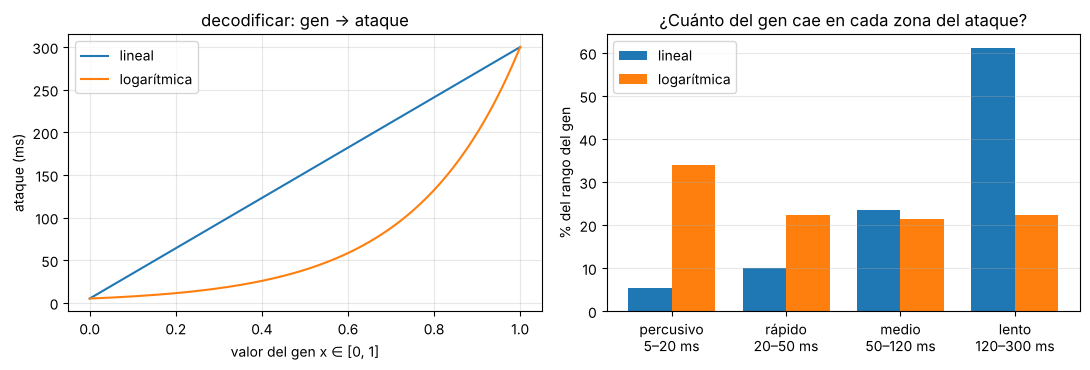

In [5]:
lo, hi = [(g[1], g[2]) for g in rol1.GENES if g[0] == "ataque"][0]
xs = np.linspace(0, 1, 201)
lineal_ms = 1000 * (lo + xs * (hi - lo))
log_ms = 1000 * np.array([rol1.decodificar(np.r_[np.zeros(8), v, np.zeros(5)])["ataque"] for v in xs])

zonas = [(5, 20, "percusivo\n5–20 ms"), (20, 50, "rápido\n20–50 ms"), (50, 120, "medio\n50–120 ms"), (120, 300, "lento\n120–300 ms")]
frac = lambda ms: [100 * np.mean((ms >= a) & (ms < b if b < 300 else ms <= b)) for a, b, _ in zonas]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(xs, lineal_ms, label="lineal"); ax[0].plot(xs, log_ms, label="logarítmica")
ax[0].set(xlabel="valor del gen x ∈ [0, 1]", ylabel="ataque (ms)", title="decodificar: gen → ataque"); ax[0].legend(); ax[0].grid(alpha=0.3)
w = 0.38; pos = np.arange(len(zonas))
ax[1].bar(pos - w/2, frac(lineal_ms), w, label="lineal"); ax[1].bar(pos + w/2, frac(log_ms), w, label="logarítmica")
ax[1].set_xticks(pos, [z[2] for z in zonas]); ax[1].set(ylabel="% del rango del gen", title="¿Cuánto del gen cae en cada zona del ataque?")
ax[1].legend(); ax[1].grid(alpha=0.3, axis="y")
fig.tight_layout(); fig.savefig(f"{GRAF}/rol1_escala_lineal_vs_log.png", dpi=130)

pd.DataFrame({"zona": [z[2].replace("\n", " ") for z in zonas], "% lineal": np.round(frac(lineal_ms), 1),
              "% logarítmica": np.round(frac(log_ms), 1)})

## 5. Tamaño del espacio de búsqueda
Los genes son continuos, así que el espacio es infinito. Para contarlo se discretiza cada gen en *k* niveles: hay *k*¹⁴ combinaciones. Se compara con las evaluaciones que hace el AG (configuración del notebook final: población 30, 50 generaciones, elitismo 2).

In [6]:
import src._provisional as P
gen_ref = P.GEN_REFERENCIA
t0 = time.perf_counter()
for _ in range(30): P._espectro_db(P.sintetizar_instrumento(*P.NOTA_PRUEBA, gen_ref))
seg_por_eval = (time.perf_counter() - t0) / 30

POB, GENS, ELITE = 30, 50, 2
evals_ag = POB + GENS * (POB - ELITE)
filas = []
for k in (10, 100, 1000):
    total = float(k) ** rol1.N_GENES
    filas.append({"niveles por gen": k, "combinaciones": f"{k}^{rol1.N_GENES} = 1e{int(np.log10(total))}",
                  "fracción explorada por el AG": f"{evals_ag / total:.1e}",
                  "años para probarlas todas": f"{total * seg_por_eval / 3.15e7:.1e}"})
df_esp = pd.DataFrame(filas); df_esp.to_csv(f"{TABLAS}/rol1_espacio_busqueda.csv", index=False)
print(f"Evaluaciones del AG por corrida: {POB} + {GENS}·({POB}-{ELITE}) = {evals_ag}")
print(f"Tiempo medido por evaluación de fitness: {1000*seg_por_eval:.1f} ms  (edad del universo ≈ 1.4e10 años)")
df_esp

Evaluaciones del AG por corrida: 30 + 50·(30-2) = 1430
Tiempo medido por evaluación de fitness: 2.5 ms  (edad del universo ≈ 1.4e10 años)


,niveles por gen,combinaciones,fracción explorada por el AG,años para probarlas todas
0,10,10^14 = 1e14,1.4e-11,7.9e+03
1,100,100^14 = 1e28,1.4e-25,7.9e+17
2,1000,1000^14 = 1e42,1.4e-39,7.9e+31


## 6. Sensibilidad: fitness vs variación de cada gen (Día 3)
Para cada gen se recorre su valor de 0 a 1 (21 niveles) dejando los demás fijos, y se mide el fitness. Se usan dos tipos de "punto fijo":

- **Alrededor del óptimo** (`codificar(GEN_REFERENCIA)`): cuánto empeora el sonido si solo ese gen se aleja del valor correcto.
- **10 fondos aleatorios**: lo mismo, pero desde individuos cualquiera, como los que hay en las primeras generaciones del AG.

**Sensibilidad** de un gen = rango del fitness (máx − mín) a lo largo del barrido, promediado sobre los fondos.

> ⚠️ El fitness real es del Rol 2. Mientras `src/rol2_fitness.py` no exista, se usa la síntesis y la referencia del **provisional**, pero decodificando con `rol1.decodificar` (escala log). Cuando el Rol 2 suba su módulo, esta celda lo carga sola: basta volver a correr el notebook.

In [7]:
try:
    rol2 = importlib.import_module("src.rol2_fitness")
    FITNESS, ORIGEN = rol2.fitness, "REAL (src/rol2_fitness.py)"
except ModuleNotFoundError:
    rol2 = P
    def FITNESS(x):  # mismo fitness que el provisional, pero con la decodificación del Rol 1
        db = P._espectro_db(P.sintetizar_instrumento(*P.NOTA_PRUEBA, rol1.decodificar(x)))
        return float(1.0 - np.mean(np.abs(db - P.REF_DB)) / 80.0)
    ORIGEN = "PROVISIONAL (síntesis y referencia de _provisional + rol1.decodificar)"
print("Fitness usado:", ORIGEN)

NIVELES = np.linspace(0, 1, 21)
N_FONDOS = 10
fondos = np.random.default_rng(SEMILLA).random((N_FONDOS, rol1.N_GENES))
x_opt = rol1.codificar(rol2.GEN_REFERENCIA) if hasattr(rol2, "GEN_REFERENCIA") else None
if x_opt is not None:
    print(f"Fitness del óptimo conocido: {FITNESS(x_opt):.4f}")

def barrido(x_base, i):
    out = []
    for v in NIVELES:
        x = x_base.copy(); x[i] = v; out.append(FITNESS(x))
    return np.array(out)

t0 = time.time()
curvas_fondo = np.array([[barrido(f, i) for f in fondos] for i in range(rol1.N_GENES)])   # [gen, fondo, nivel]
curvas_opt = np.array([barrido(x_opt, i) for i in range(rol1.N_GENES)]) if x_opt is not None else None
print(f"{curvas_fondo.size + (0 if curvas_opt is None else curvas_opt.size)} evaluaciones en {time.time()-t0:.1f} s")

Fitness usado: PROVISIONAL (síntesis y referencia de _provisional + rol1.decodificar)
Fitness del óptimo conocido: 1.0000


3234 evaluaciones en 9.0 s


,gen,sensibilidad_fondos,sensibilidad_optimo,valor_optimo_x
0,sostenido,0.0246,0.0213,0.150
1,vib_prof,0.0120,0.0000,0.000
2,liberacion,0.0115,0.0037,0.785
3,amp_h1,0.0100,0.0196,1.000
4,amp_h8,0.0079,0.0088,0.020
5,amp_h2,0.0071,0.0081,0.550
6,amp_h7,0.0066,0.0068,0.050
7,vib_frec,0.0064,0.0000,0.000
8,decaimiento,0.0063,0.0118,0.796
9,amp_h3,0.0063,0.0082,0.350


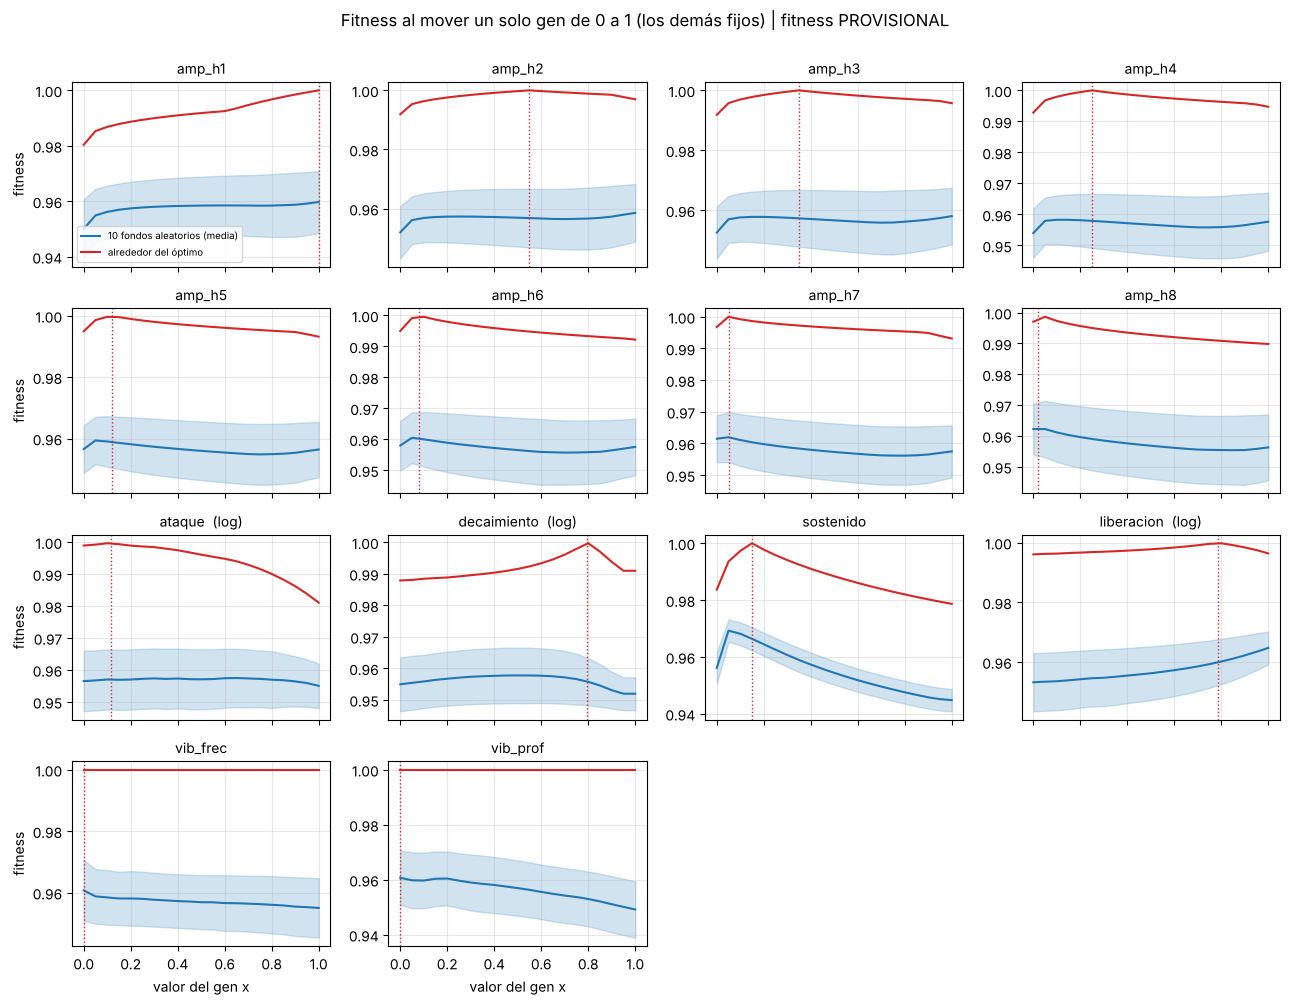

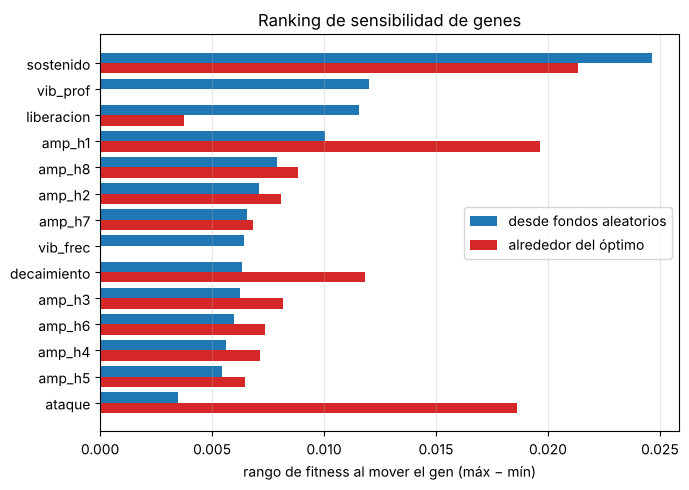

In [8]:
nombres = [g[0] for g in rol1.GENES]
sens_fondo = (curvas_fondo.max(axis=2) - curvas_fondo.min(axis=2)).mean(axis=1)
df_sens = pd.DataFrame({"gen": nombres, "sensibilidad_fondos": sens_fondo})
if curvas_opt is not None:
    df_sens["sensibilidad_optimo"] = curvas_opt.max(axis=1) - curvas_opt.min(axis=1)
    df_sens["valor_optimo_x"] = np.round(x_opt, 3)
df_sens = df_sens.sort_values("sensibilidad_fondos", ascending=False).reset_index(drop=True)
df_sens.to_csv(f"{TABLAS}/rol1_sensibilidad_genes.csv", index=False)

# --- curvas por gen
fig, axs = plt.subplots(4, 4, figsize=(13, 10), sharex=True)
for i, ax in enumerate(axs.flat):
    if i >= rol1.N_GENES: ax.axis("off"); continue
    media, desv = curvas_fondo[i].mean(0), curvas_fondo[i].std(0)
    ax.plot(NIVELES, media, color="C0", label="10 fondos aleatorios (media)")
    ax.fill_between(NIVELES, media - desv, media + desv, color="C0", alpha=0.2)
    if curvas_opt is not None:
        ax.plot(NIVELES, curvas_opt[i], color="C3", label="alrededor del óptimo")
        ax.axvline(x_opt[i], color="C3", ls=":", lw=1)
    ax.set_title(nombres[i] + ("  (log)" if nombres[i] in rol1.ESCALA_LOG else ""), fontsize=10); ax.grid(alpha=0.3)
for ax in axs[-1]: ax.set_xlabel("valor del gen x")
for ax in axs[:, 0]: ax.set_ylabel("fitness")
axs.flat[0].legend(fontsize=7, loc="lower left")
fig.suptitle(f"Fitness al mover un solo gen de 0 a 1 (los demás fijos) | fitness {ORIGEN.split()[0]}", y=1.0)
fig.tight_layout(); fig.savefig(f"{GRAF}/rol1_sensibilidad_genes.png", dpi=130, bbox_inches="tight")

# --- ranking
fig, ax = plt.subplots(figsize=(7, 5))
yy = np.arange(len(df_sens))[::-1]
ax.barh(yy + 0.2, df_sens["sensibilidad_fondos"], 0.4, color="C0", label="desde fondos aleatorios")
if curvas_opt is not None:
    ax.barh(yy - 0.2, df_sens["sensibilidad_optimo"], 0.4, color="C3", label="alrededor del óptimo")
ax.set_yticks(yy, df_sens["gen"]); ax.set(xlabel="rango de fitness al mover el gen (máx − mín)", title="Ranking de sensibilidad de genes")
ax.legend(); ax.grid(alpha=0.3, axis="x")
fig.tight_layout(); fig.savefig(f"{GRAF}/rol1_ranking_sensibilidad.png", dpi=130)
df_sens.round(4)

In [9]:
# Resumen automático para reportar al Rol 2 (se actualiza solo al volver a correr con el fitness real)
s = df_sens.set_index("gen")["sensibilidad_fondos"]
umbral = 0.25 * s.max()
print(f"Fitness usado: {ORIGEN}\n")
print("Genes MÁS sensibles :", ", ".join(f"{g} ({v:.3f})" for g, v in s.head(4).items()))
print("Genes MENOS sensibles:", ", ".join(f"{g} ({v:.3f})" for g, v in s.tail(4).items()))
print(f"Genes con sensibilidad < 25% del máximo ({umbral:.3f}): {', '.join(s[s < umbral].index)}")

Fitness usado: PROVISIONAL (síntesis y referencia de _provisional + rol1.decodificar)

Genes MÁS sensibles : sostenido (0.025), vib_prof (0.012), liberacion (0.012), amp_h1 (0.010)
Genes MENOS sensibles: amp_h6 (0.006), amp_h4 (0.006), amp_h5 (0.005), ataque (0.003)
Genes con sensibilidad < 25% del máximo (0.006): amp_h6, amp_h4, amp_h5, ataque


## Conclusiones del Rol 1
Las conclusiones redactadas y la justificación de cada decisión están en `informe/rol1_codificacion.md`.